In [1]:
import pandas as pd
import numpy as np

# Read in file
df = pd.read_csv('data/wetlands_seasonal_bird_diversity.csv')

# Check the first 5 rows
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'data/wetlands_seasonal_bird_diversity.csv'

<Axes: >

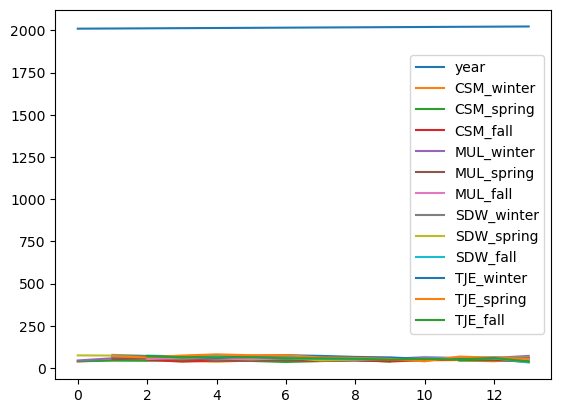

In [2]:
# Default plot(): one line plot per column with numeric data
# This is nonsensical as year is being plotted with everything else
df.plot()

### Single Line Plots

In [3]:
# General syntax for making a line plot of one column against another:
# df.plot(x='x_values_column', y='y_values_column')

<Axes: xlabel='year'>

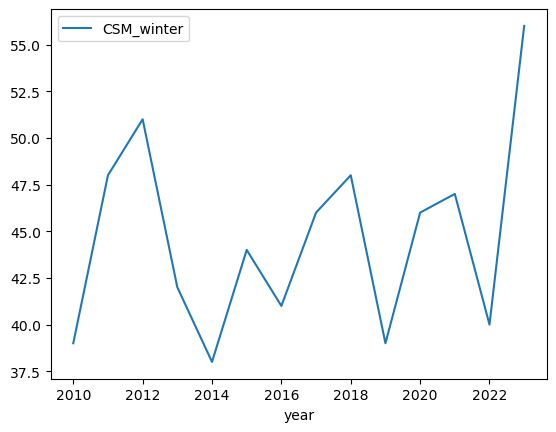

In [4]:
# Bird species registered during winter at CSM yearly
df.plot(x='year', y='CSM_winter')

Basic PLot customisations:

title: title to use for the plot.
xlabel: name to use for the x-label on x-axis
ylabel: name to use for the y-label on y-axis
color: change the color of our plot
legend: boolean value True or False. True (default) includes the legend, False removes the legend

<Axes: title={'center': 'Bird species registered during winter at Carpinteria Salt Marsh'}, xlabel='Year', ylabel='Number of bird species'>

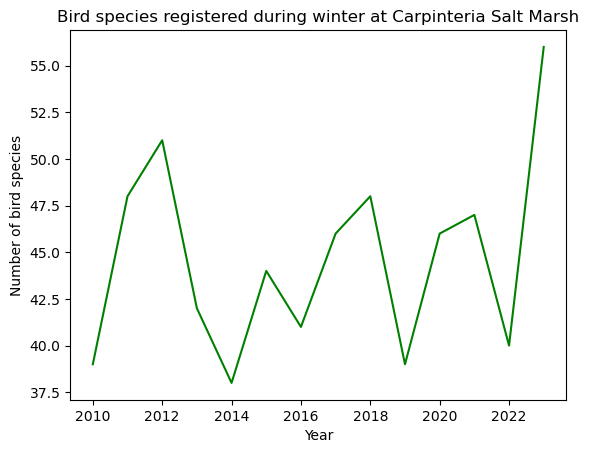

In [5]:
df.plot(x = 'year', 
        y = 'CSM_winter',
        title = 'Bird species registered during winter at Carpinteria Salt Marsh',
        xlabel = 'Year',
        ylabel = 'Number of bird species',
        color = 'green',
        legend = False
        )

Check-in:
1. Plot a graph of the spring bird surveys at Mugu Lagoon with respect to the years. Include some basic customization.
2. Use the isna() method for pandas.Series and row selection to select the rows in which Mugu Lagoon has NAs during the spring survey.

<Axes: title={'center': 'Bird species registered during spring at Mugu Lagoon'}, xlabel='Year', ylabel='Number of bird species'>

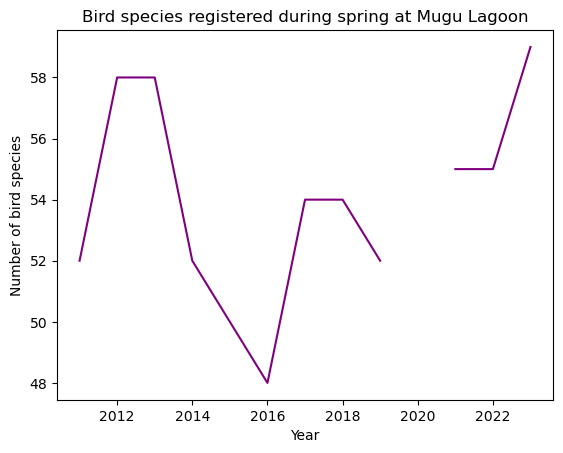

In [6]:
# 1.
df.plot(x = 'year', 
        y = 'MUL_spring',
        title = 'Bird species registered during spring at Mugu Lagoon',
        xlabel = 'Year',
        ylabel = 'Number of bird species',
        color = 'purple',
        legend = False
        )

In [7]:
# 2. 
sp_mugu_raw = pd.Series(df['MUL_spring'])
sp_mugu = sp_mugu_raw[sp_mugu_raw.notna()]
sp_mugu_raw.isna()

0      True
1     False
2     False
3     False
4     False
5     False
6     False
7     False
8     False
9     False
10     True
11    False
12    False
13    False
Name: MUL_spring, dtype: bool

In [37]:
# In-Class Solution # 2:
df[df['MUL_spring'].isna()]

,year,CSM_winter,CSM_spring,CSM_fall,MUL_winter,MUL_spring,MUL_fall,SDW_winter,SDW_spring,SDW_fall,TJE_winter,TJE_spring,TJE_fall
0,2010,39.0,40.0,50.0,45.0,NaN,61.0,NaN,75.0,85.0,NaN,NaN,81.0
10,2020,46.0,NaN,47.0,56.0,NaN,66.0,57.0,NaN,58.0,54.0,40.0,54.0


### Multi Line Plots

Multiple line plots by updating these parameters in the plot() method:

y : a list of column names that will be plotted against the x-axis
color: a dictionary {'column_1' : 'color_1', 'column_2':'color_2'} specifying the color of each column’s line plot

<Axes: title={'center': 'Seasonal bird surveys at Tijuana Estuary'}, xlabel='Year', ylabel='Number of bird species'>

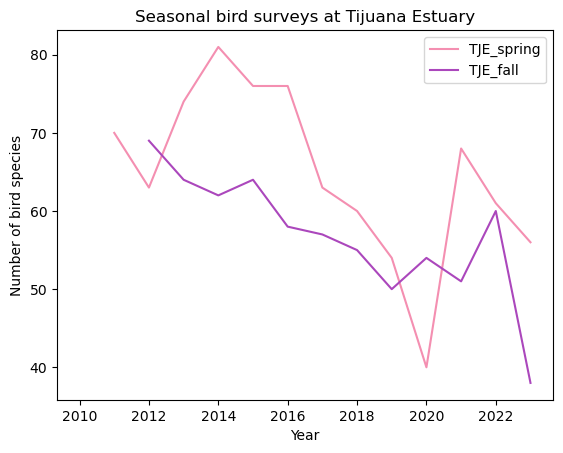

In [9]:
# Comparing bird surveys at the Tijuana Estuary in spring and fall across years:
df.plot(x = 'year', 
        y = ['TJE_spring', 'TJE_fall'],
        title = 'Seasonal bird surveys at Tijuana Estuary',
        xlabel = 'Year',
        ylabel = 'Number of bird species',        
        color = {'TJE_spring':'#F48FB1',
                 'TJE_fall': '#AB47BC'
                 }
        )

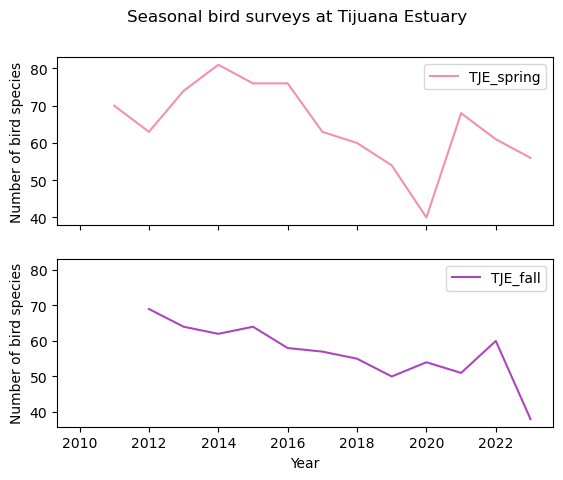

In [10]:
# Create separate plots for each column by setting the subplots parameter to True
df.plot(x = 'year', 
        y = ['TJE_spring', 'TJE_fall'],
        title = 'Seasonal bird surveys at Tijuana Estuary',
        xlabel = 'Year',
        ylabel = 'Number of bird species',        
        color = {'TJE_spring':'#F48FB1',
                 'TJE_fall': '#AB47BC'
                 },
        subplots = True
        );

### Updating the Index

In [11]:
# General syntax for updating the index:
# df = df.set_index(new_index)

Where new_index is:
 - The name of the column in the data frame df we want to use as new index
 - If our new index is not a column in the data frame, an array or pandas.Series of the same length as our data frame (we need one index per row)

In [12]:
# Two options to update the dataframe:

# Set `column_name` column in df as the new index (reassignment)
# df = df.set_index('column_name')

# Set `column_name` column in df as the new index (modify df in-place)
# df.set_index('column_name', inplace=True)

In [13]:
# Update index to be the year column
df = df.set_index('year')
df.head()

,CSM_winter,CSM_spring,CSM_fall,MUL_winter,MUL_spring,MUL_fall,SDW_winter,SDW_spring,SDW_fall,TJE_winter,TJE_spring,TJE_fall
year,,,,,,,,,,,,
2010,39.0,40.0,50.0,45.0,NaN,61.0,NaN,75.0,85.0,NaN,NaN,81.0
2011,48.0,44.0,NaN,58.0,52.0,NaN,78.0,74.0,NaN,67.0,70.0,NaN
2012,51.0,43.0,49.0,57.0,58.0,53.0,71.0,72.0,73.0,70.0,63.0,69.0
2013,42.0,46.0,38.0,60.0,58.0,62.0,69.0,70.0,70.0,69.0,74.0,64.0
2014,38.0,43.0,45.0,49.0,52.0,57.0,61.0,78.0,71.0,60.0,81.0,62.0


<Axes: xlabel='year'>

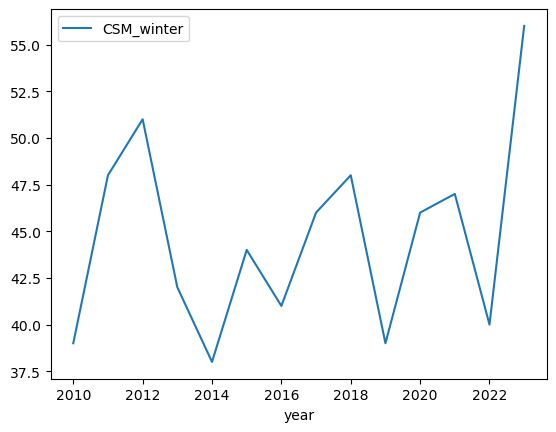

In [14]:
# Simple plot of Carpinteria Salt Marsh winter surveys, x = year implied from index
df.plot(y='CSM_winter')

In [15]:
# To get back to numbered index:
df = df.reset_index()
df.head()

,year,CSM_winter,CSM_spring,CSM_fall,MUL_winter,MUL_spring,MUL_fall,SDW_winter,SDW_spring,SDW_fall,TJE_winter,TJE_spring,TJE_fall
0,2010,39.0,40.0,50.0,45.0,NaN,61.0,NaN,75.0,85.0,NaN,NaN,81.0
1,2011,48.0,44.0,NaN,58.0,52.0,NaN,78.0,74.0,NaN,67.0,70.0,NaN
2,2012,51.0,43.0,49.0,57.0,58.0,53.0,71.0,72.0,73.0,70.0,63.0,69.0
3,2013,42.0,46.0,38.0,60.0,58.0,62.0,69.0,70.0,70.0,69.0,74.0,64.0
4,2014,38.0,43.0,45.0,49.0,52.0,57.0,61.0,78.0,71.0,60.0,81.0,62.0


Check-in:
1. Without running the code, give a step-by-step breakdown of what this code is doing:
df.set_index('year').loc[:,'SDW_winter':'TJE_fall'].plot()

This code is setting the index of the dataframe to the year column, selecting columns from SDW_winter to TJE_fall, and plotting those columns as individual lines againt the index (year).

2. Is this code modifying the data frame df? Why or why not?

No, this code is not modifying the dataframe because it does not either reassign the dataframe of modify the dataframe using inplace = True.

3. Run the code and examine the graph. Review the data description. Do we have all the necessary information to make sure it makes sense to directly compare the surveys at these different sites?

I cannot find the data description. If there are differences in something like search effort or frequency of searches, it might not make sense to compare between sites like this.

<Axes: xlabel='year'>

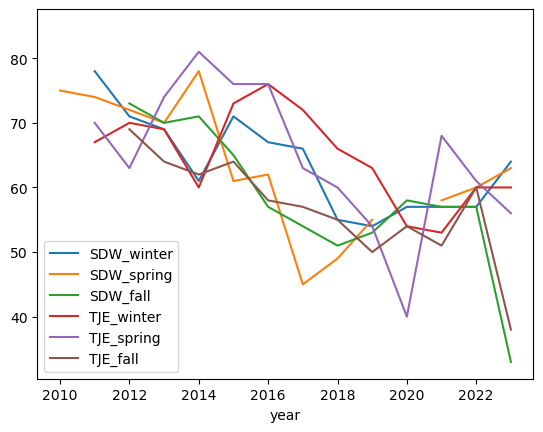

In [16]:
df.set_index('year').loc[:,'SDW_winter':'TJE_fall'].plot()

### Method Chaining

In [17]:
# This long method chain we just used:
# df.set_index('year').loc[:,'SDW_winter':'TJE_fall'].plot()

# Can be broken up using parenthesis like this:
# (df.set_index('year')
# .loc[:,'SDW_winter':'TJE_fall']
# .plot()
# )

In [18]:
# This could be an alternative to the code chaining, but contains many variables tha aren't needed for anything else:
# year_index_df = df.set_index('year')
# subset_df = year_index_df.loc[:,'SDW_winter':'TJE_fall']
# subset_df.plot()

### About the Data: Data Exploration of Palmers Penguins

In [3]:
# Read in data
URL = 'https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv'
penguins = pd.read_csv(URL)

penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [4]:
# Check column data types and NA values
penguins.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB


In [5]:
# Simple statistics about numeric columns
penguins.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


In [6]:
# Count unique values in categorical columns and year
penguins[['species', 'island', 'sex', 'year']].nunique()

species    3
island     3
sex        2
year       3
dtype: int64

In [7]:
# Get unique values in species column
penguins['species'].unique()

array(['Adelie', 'Gentoo', 'Chinstrap'], dtype=object)

In [8]:
# Number of values per unique value in species column
penguins['species'].value_counts()

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

The kind argument in plot() changes what kind of plot the function makes, line is just the default

### Scatter Plots

<Axes: xlabel='flipper_length_mm', ylabel='body_mass_g'>

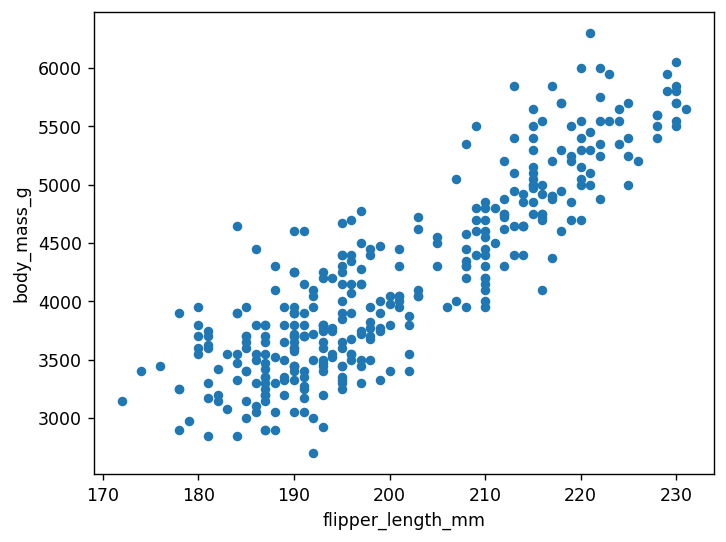

In [9]:
# Visually compare flipper length and body mass:
penguins.plot(kind='scatter',
              x='flipper_length_mm', 
              y='body_mass_g')

<Axes: title={'center': 'Flipper length and body mass for Palmer penguins'}, xlabel='Flipper length (mm)', ylabel='Body mass (g)'>

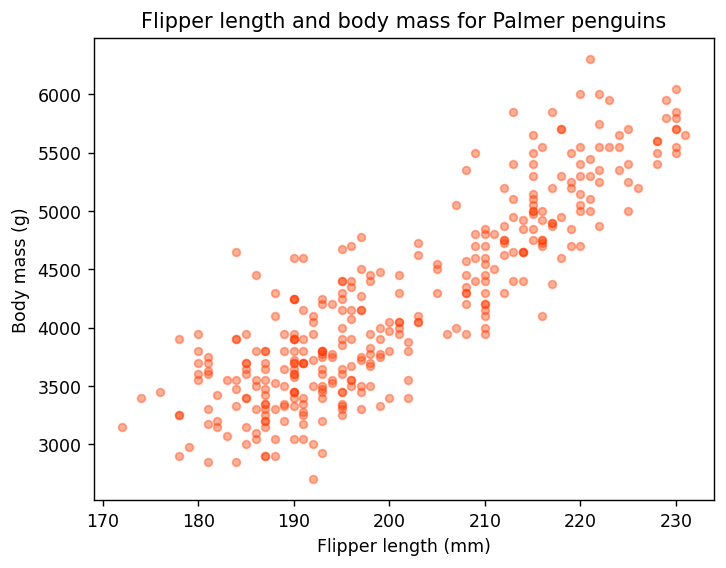

In [10]:
# Customising the basic plot:
penguins.plot(kind='scatter',
              x='flipper_length_mm', 
              y='body_mass_g',
              title='Flipper length and body mass for Palmer penguins',
              xlabel='Flipper length (mm)',
              ylabel='Body mass (g)',
              color='#ff3b01',
              alpha=0.4  # Controls transparency
              )

### Bar Plots

In [11]:
# 10 penguins with the smallest body mass:
smallest = penguins['body_mass_g'].nsmallest(10)
smallest

314    2700.0
58     2850.0
64     2850.0
54     2900.0
98     2900.0
116    2900.0
298    2900.0
104    2925.0
47     2975.0
44     3000.0
Name: body_mass_g, dtype: float64

<Axes: >

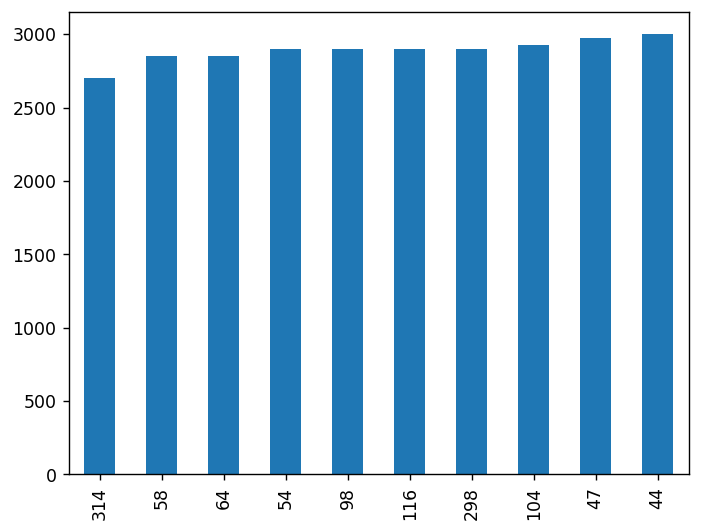

In [12]:
# Bar plotting the smallest penguins:
smallest.plot(kind='bar')

In [14]:
# To look at other data for smallest penguins:
penguins.nsmallest(10, 'body_mass_g')

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
314,Chinstrap,Dream,46.9,16.6,192.0,2700.0,female,2008
58,Adelie,Biscoe,36.5,16.6,181.0,2850.0,female,2008
64,Adelie,Biscoe,36.4,17.1,184.0,2850.0,female,2008
54,Adelie,Biscoe,34.5,18.1,187.0,2900.0,female,2008
98,Adelie,Dream,33.1,16.1,178.0,2900.0,female,2008
116,Adelie,Torgersen,38.6,17.0,188.0,2900.0,female,2009
298,Chinstrap,Dream,43.2,16.6,187.0,2900.0,female,2007
104,Adelie,Biscoe,37.9,18.6,193.0,2925.0,female,2009
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN,2007
44,Adelie,Dream,37.0,16.9,185.0,3000.0,female,2007


### Histograms

<Axes: ylabel='Frequency'>

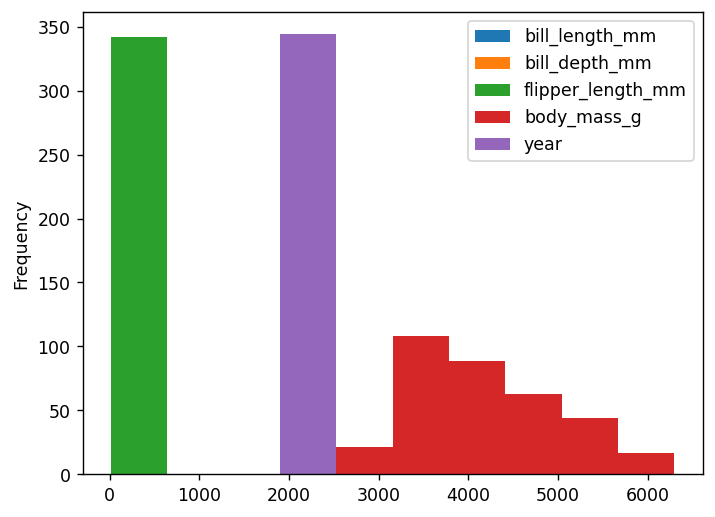

In [15]:
# Using plot without subsetting data - a mess again
penguins.plot(kind='hist')

<Axes: title={'center': 'Penguin flipper lengths'}, xlabel='Flipper length (mm)', ylabel='Frequency'>

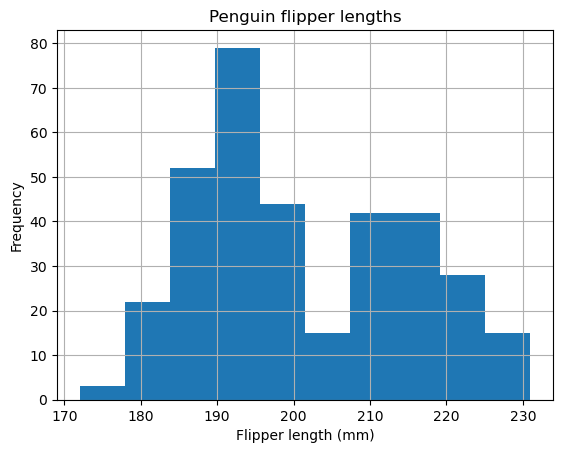

In [31]:
# Subsetting for flipper length:
# Distribution of flipper length measurements
# First select data, then plot
penguins['flipper_length_mm'].plot(kind='hist',
                                title='Penguin flipper lengths',
                                xlabel='Flipper length (mm)',
                                grid=True)

Check-in:
1. Select the bill_length_mm and bill_depth_mm columns in the penguins data frame and then update the kind parameter to box to make boxplots of the bill length and bill depth.
2. Create a simple histogram of the flipper length of female gentoo penguins.

<Axes: >

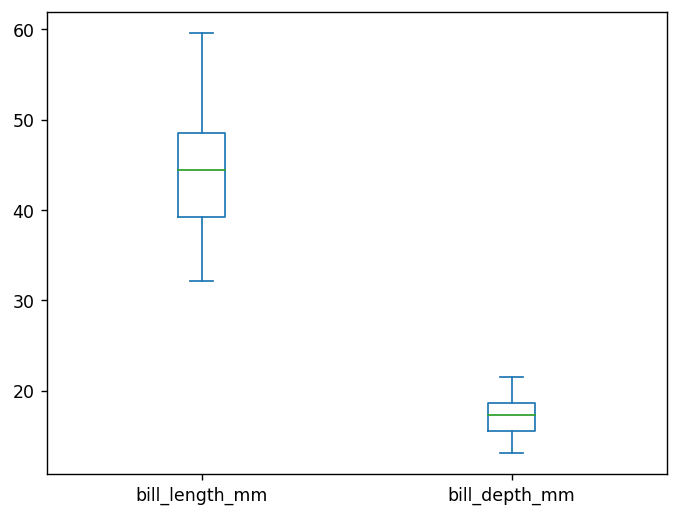

In [16]:
# 1.
penguins.loc[:, ['bill_length_mm', 'bill_depth_mm']].plot(kind='box')

<Axes: title={'center': 'Female Gentoo Flipper Length (mm)'}, ylabel='Frequency'>

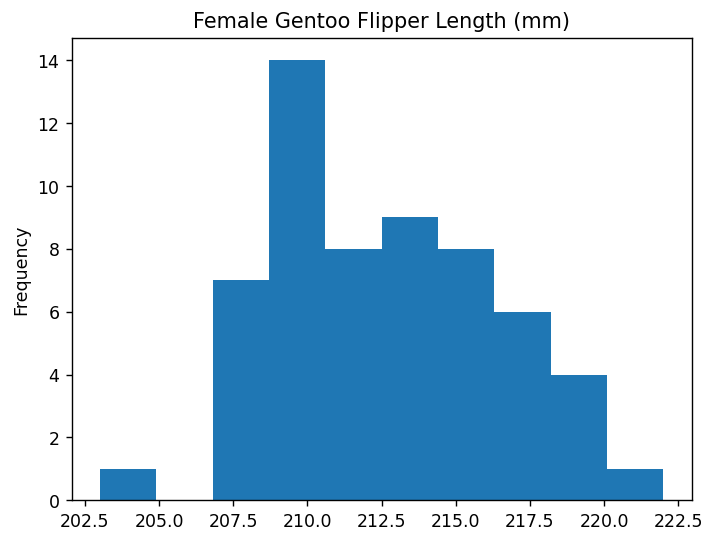

In [18]:
# 2. 
penguins.loc[(penguins['sex'] == 'female') & (penguins['species'] == 'Gentoo'), 'flipper_length_mm'].plot(kind = 'hist', title = 'Female Gentoo Flipper Length (mm)')